> **Telecommunication Lab Exam | Experiment 1**  
> Based on *Telecommunication-Lab.pdf*, PDF pages 2–4.  
> **Use:** Read the theory → run the two code cells → identify the output → practice the viva answers.  
> **Software:** Python 3, Jupyter/Colab, `numpy`, `matplotlib`. **Only Exp 1 optionally needs `scipy`.**


# Experiment 1 — Pulse Code Modulation (PCM) & Demodulation

**Aim (manual):** Generate Pulse Code Modulation and Demodulation using MATLAB. This notebook implements the same basic stages in Python.

## 1. Theory / principle

**PCM** represents the amplitude of an analog message by a finite binary word at each sampling instant.

**Transmitter:** analog message → low-pass (anti-alias) filter → sampler → quantizer → binary encoder → PCM bits.  
**Receiver:** PCM bits → regeneration/decoder → reconstruction low-pass filter → approximate analog message.

- **Sampling:** Take discrete-time samples of a continuous analog signal.
- **Quantization:** Replace each sample with the nearest allowed amplitude level (finite precision).
- **Encoding:** Assign a binary code to each level; the result is the PCM bitstream.
- **Decoding / reconstruction:** Recover quantized amplitudes and smooth the signal with an LPF.

### Essential formulas

Message signal:

$$x(t) = A\sin(2\pi f_m t)$$

Sampling theorem (for a bandlimited signal):

$$f_s \geq 2f_{\max}$$

For a **uniform** quantizer with $L$ levels, $n$ bits per sample and input range $x_{\min}$ to $x_{\max}$:

$$L=2^n,\qquad \Delta=\frac{x_{\max}-x_{\min}}{L}$$

The PCM bit rate is:

$$R_b=n f_s\quad\text{bits/second}$$

Quantization error:

$$e_q=x-x_q$$


## 2. Values used in the lab manual

| Quantity | Value |
|---|---:|
| Sine amplitude $A$ | $4$ |
| Message frequency $f_m$ | $2\,\mathrm{Hz}$ |
| Sampling frequency $f_s$ | $200\,\mathrm{Hz}$ ($100f_m$) |
| Quantizer input range | $-4$ to $+4$ |
| Levels $L$ | 8, at $-3.5,-2.5,\ldots,3.5$ |
| Bits per sample $n$ | $\log_2 8=3$ |
| Step size $\Delta$ | $1$ |
| Demo PCM bit rate | $3\times200=600\,\mathrm{bit/s}$ |

**Encoding example:** input amplitude $+2.2$ → quantized amplitude $+2.5$ → binary word `110`.  
At $x=0$, the manual's interval rule maps to $-0.5$ → `011` (a **mid-rise** quantizer).

**Manual's plots:** Original, sampled, quantized, decoded, reconstructed (5 plots). This notebook **adds the PCM bits** as a sixth useful plot.

**Filtering detail:** The manual uses a sixth-order Butterworth reconstruction LPF (`butter(6,4*fm/fs)`). The code below uses it **when SciPy is available**; otherwise a simpler first-order LPF is used. The reconstructed wave resembles the original but is not identical.


## 3. Runnable Python implementation

**Run the next cell** to compute the signal and print essential results. The following cell draws the output waveforms. Use **Run All** to execute both in order.

In [3]:
"""Experiment 1: 3-bit PCM, quantization, decoding and reconstruction."""
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate Original Message Signal
A, fm, fs = 4, 2, 200
t = np.arange(fs + 1) / fs
x = A * np.sin(2 * np.pi * fm * t)

# 2. Quantization (8 levels = 3 bits)
levels = np.arange(-3.5, 4, 1)
index = np.ceil(x + 4).astype(int) - 1
index = np.clip(index, 0, 7)
xq = levels[index]

# 3. PCM Encoding (Decimal to 3-bit Binary)
codes = [format(i, '03b') for i in index]
bits = [int(b) for code in codes for b in code]

# 4. PCM Decoding (Binary to Quantized Values)
decoded = np.array([levels[int(code, 2)] for code in codes])

# 5. (Optional) Signal Reconstruction using Low-Pass Filter 
try:
    # Sixth-order Butterworth LPF (if SciPy is installed)
    from scipy.signal import butter, lfilter

    b, a = butter(6, 4*fm/fs)
    reconstructed = lfilter(b, a, decoded)
    print("Using Butterworth Low-Pass Filter")

except ImportError:
    # (Optional) Simple first-order LPF (without SciPy)
    alpha = 1 - np.exp(-2*np.pi*(2*fm)/fs)
    reconstructed = np.zeros_like(decoded)

    for i in range(len(decoded)):
        previous = reconstructed[i-1] if i > 0 else 0
        reconstructed[i] = alpha*decoded[i] + (1-alpha)*previous

    print("Using Simple Low-Pass Filter")

# 6. Display Results
print("First 10 PCM Codes:", codes[:10])
print("PCM Bit Rate:", 3*fs, "bits/s")

Using Butterworth Low-Pass Filter
First 10 PCM Codes: ['011', '100', '100', '100', '100', '101', '101', '101', '101', '110']
PCM Bit Rate: 600 bits/s


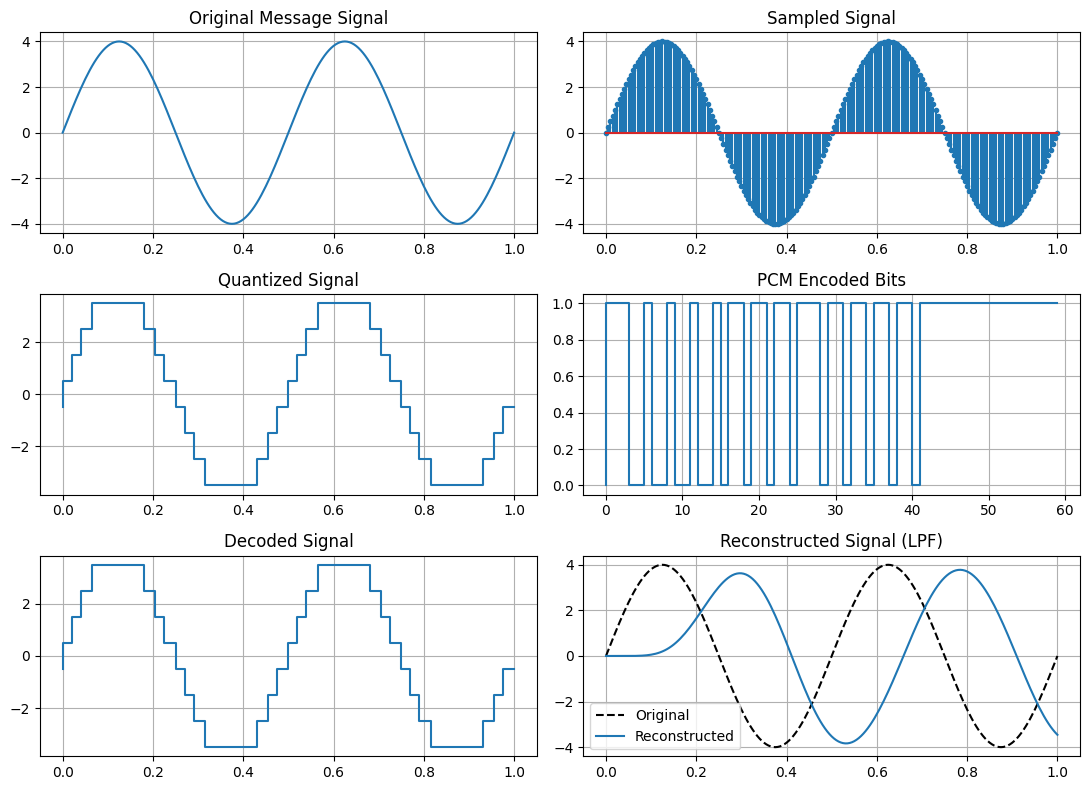

In [4]:
# 7. Plot All Waveforms
fig, ax = plt.subplots(3, 2, figsize=(11, 8))

ax[0, 0].plot(t, x)
ax[0, 0].set_title("Original Message Signal")

ax[0, 1].stem(t, x, markerfmt='.')
ax[0, 1].set_title("Sampled Signal")

ax[1, 0].step(t, xq)
ax[1, 0].set_title("Quantized Signal")

ax[1, 1].step(range(60), bits[:60])
ax[1, 1].set_title("PCM Encoded Bits")

ax[2, 0].step(t, decoded)
ax[2, 0].set_title("Decoded Signal")

ax[2, 1].plot(t, x, 'k--', label="Original")
ax[2, 1].plot(t, reconstructed, label="Reconstructed")
ax[2, 1].legend()
ax[2, 1].set_title("Reconstructed Signal (LPF)")

# 8. Graph Formatting
for axis in ax.flat:
    axis.grid(True)

plt.tight_layout()
plt.show()

## 4. What you should observe

1. **Original message:** smooth sine wave of amplitude about $\pm4$.
2. **Sampled message:** discrete samples following the sine curve.
3. **Quantized:** staircase amplitudes at $-3.5$ to $+3.5$.
4. **PCM bits:** sequence of `0` and `1`, grouped in sets of 3.
5. **Decoded signal:** the receiver recovers the quantized amplitude levels.
6. **Reconstructed:** smooth approximation of the original sine wave, sometimes with filter start-up delay.

Expected first 12 PCM codewords (manual mapping):  
`011 100 100 100 100 101 101 101 101 110 110 110`

**Result to write:** Pulse Code Modulation and Demodulation were performed; the analog signal was sampled, quantized into 8 levels, encoded as 3-bit words, decoded and approximately reconstructed.

## 5. Viva — short answers

**Q1. What is PCM?** Digital representation of analog samples using binary codewords.  
**Q2. Sampling vs quantization?** Sampling discretizes **time**; quantization discretizes **amplitude**.  
**Q3. Why 3 bits?** $2^3=8$ quantization levels.  
**Q4. Nyquist condition?** $f_s \ge 2f_{\max}$. Here $200\gg4\,\mathrm{Hz}$.  
**Q5. What causes quantization noise?** Rounding each sample to one of the allowed levels.  
**Q6. Why use an LPF at the receiver?** To smooth the quantized waveform and suppress high-frequency components.  
**Q7. Why can the output differ from the input?** Quantization error plus practical reconstruction filtering.  
**Q8. What is the bit rate here?** $600\,\mathrm{bit/s}$.

**Practice:** Identify each waveform without reading its title, then explain the stages in order.
